# 09 - Classification Model Comparison

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Compare multiple classifiers with the same train/test split and metrics.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [2]:
dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dataset.target)

## Define and evaluate models

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111
4,SVM,0.982456,0.986111,0.986111,0.986111
1,KNN,0.956140,0.958904,0.972222,0.965517
3,Random Forest,0.956140,0.958904,0.972222,0.965517
2,Decision Tree,0.938596,0.957746,0.944444,0.951049


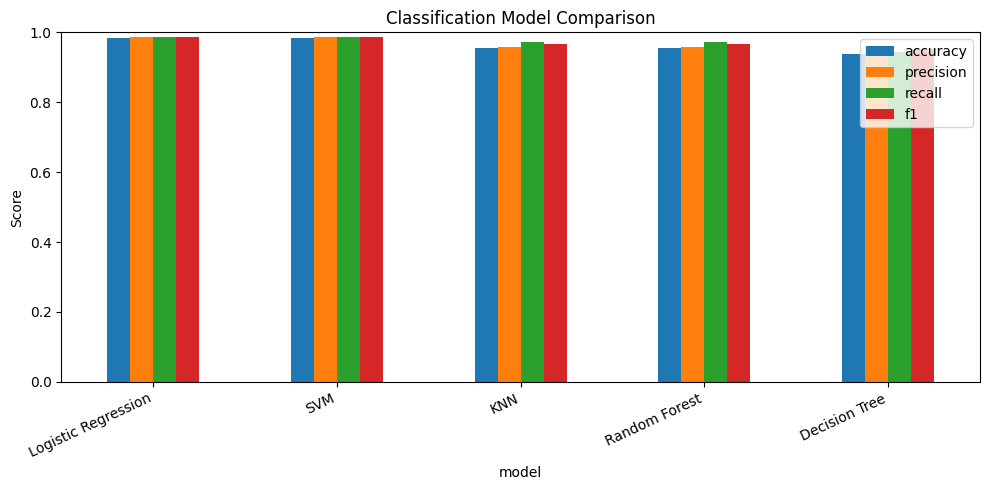

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel="rbf"))])
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred)})

comparison = pd.DataFrame(rows).sort_values("f1", ascending=False)
display(comparison)
comparison.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Exercises
1. Add a `DummyClassifier` baseline.
2. Explain why a single test split can give an unstable estimate.
3. Try macro-averaged F1 on a multiclass dataset.